# 07 - Sistemas não lineares
Vamos aprender sobre como usar o método iterativo de Newton-Raphson adaptado aos sistemas de equações, envolvendo aproximações iniciais, cálculo da matriz do Jacobiano e critério de parada, para resolução de sistemas não lineares.

Crie uma nova branch (versão) do repositório:

```bash
git branch semana7
```

Faça o checkout nessa nova branch:

```bash
git checkout semana7
```

<hr />

## Atividade 1
Escreva o método iterativo de Newton-Raphson adaptado dentro do arquivo $utils/algoritmos.py$.

In [ ]:
import numpy as np
from scipy.optimize import approx_fprime


def JN(x, F, eps=1e-8):
    x = np.asarray(x, dtype=float)
    n = x.size
    Jnum = np.zeros((n, n), dtype=float)

    def fi(v):
        return F(v)[i]

    for i in range(n):
        Jnum[i, :] = approx_fprime(x, fi, epsilon=eps)

    return Jnum


def G(x, F, J):
    return x - np.linalg.inv(J(x)) @ F(x)


def GN(x, F):
    return x - np.linalg.inv(JN(x, F)) @ F(x)


def fixed_point(a, g, TOL=1e-8, iter=1000):
    x = g(a)
    i = 1
    while np.linalg.norm(x - a) > TOL and i < iter:
        a = x
        x = g(a)
        i += 1
    return x

Encontre uma aproximação numérica para o seguinte problema não linear de três equações e três incógnitas:

$$
2x_{1} - x_{2} = \cos(x_{1})
$$

$$
- x_{1} + 2x_{2} - x_{3} = \cos(x_{2})
$$

$$
- x_{2} + x_{3} = \cos(x_{3})
$$

Partindo da seguinte aproximação inicial:

$$
x^{(0)} = (1,\,1,\,1)^{T}
$$

In [2]:
import sys
import os
import numpy as np

# Sobe um nível para a raiz do projeto e adiciona ao caminho do sistema
sys.path.append(os.path.abspath(os.path.join('..')))

from utils.algoritmos import (
    G,
    GN,
    fixed_point,
)


def main():

    def F(x):
        x1, x2, x3 = x
        return np.array(
            [
                2.0 * x1 - x2 - np.cos(x1),
                -x1 + 2.0 * x2 - x3 - np.cos(x2),
                -x2 + x3 - np.cos(x3),
            ],
            dtype=float,
        )

    def J(x):
        x1, x2, x3 = x
        return np.array(
            [
                [2.0 + np.sin(x1), -1.0, 0.0],
                [-1.0, 2.0 + np.sin(x2), -1.0],
                [0.0, -1.0, 1.0 + np.sin(x3)],
            ],
            dtype=float,
        )

    x = np.array([1.0, 1.0, 1.0], dtype=float)
    r = fixed_point(x, lambda x: G(x, F, J))
    print(r)
    r = fixed_point(x, lambda x: GN(x, F))
    print(r)


if __name__ == "__main__":
    main()

[0.95127255 1.32189759 1.44618584]
[0.95127255 1.32189759 1.44618584]


## Atividade 2
Encontre uma aproximação em cada incógnita para a solução próxima da origem do sistema:

$$
6x - 2y + e^{z} = 2
$$

$$
\sin(x) - y + z = 0
$$

$$
\sin(x) + 2y + 3z = 1
$$

**Resposta esperada:**

$$
x \approx 0.259751, \quad y \approx 0.302736, \quad z \approx 0.045896
$$

In [1]:
import numpy as np


def system(values):
    x_value, y_value, z_value = values
    return np.array(
        [
            6 * x_value - 2 * y_value + np.exp(z_value) - 2,
            np.sin(x_value) - y_value + z_value,
            np.sin(x_value) + 2 * y_value + 3 * z_value - 1,
        ],
        dtype=float,
    )


def jacobian(values):
    x_value, _, z_value = values
    return np.array(
        [
            [6.0, -2.0, np.exp(z_value)],
            [np.cos(x_value), -1.0, 1.0],
            [np.cos(x_value), 2.0, 3.0],
        ],
        dtype=float,
    )


solution = np.zeros(3, dtype=float)
tolerance = 1e-12
max_iterations = 100

for iteration in range(1, max_iterations + 1):
    correction = np.linalg.solve(jacobian(solution), -system(solution))
    solution += correction
    if np.linalg.norm(correction, ord=np.inf) < tolerance:
        break
else:
    raise RuntimeError("Newton-Raphson não convergiu dentro do limite de iterações.")

residual = np.linalg.norm(system(solution), ord=np.inf)
assert residual < 1e-12
assert np.allclose(solution, [0.259751, 0.302736, 0.045896], atol=1e-5)

print(f"x ≈ {solution[0]:.9f}")
print(f"y ≈ {solution[1]:.9f}")
print(f"z ≈ {solution[2]:.9f}")
print(f"Iterações: {iteration}; norma do resíduo: {residual:.3e}")

x ≈ 0.259751077
y ≈ 0.302735995
z ≈ 0.045896008
Iterações: 4; norma do resíduo: 2.220e-16


## Atividade 3
Considere o problema de encontrar os pontos de interseção das curvas descritas:

$$
\frac{x^{2}}{8} + \frac{(y-1)^{2}}{5} = 1
$$

$$
\tan^{-1}(x) + x = y + y^{3}
$$

Com base no gráfico, encontre soluções aproximadas para o problema e use-as para iniciar o método de Newton-Raphson para encontrar as raízes.

**Resposta esperada:**

$$
(-1.2085435,\,-1.0216674) 
\quad \text{e} \quad 
(2.7871115,\,1.3807962)
$$

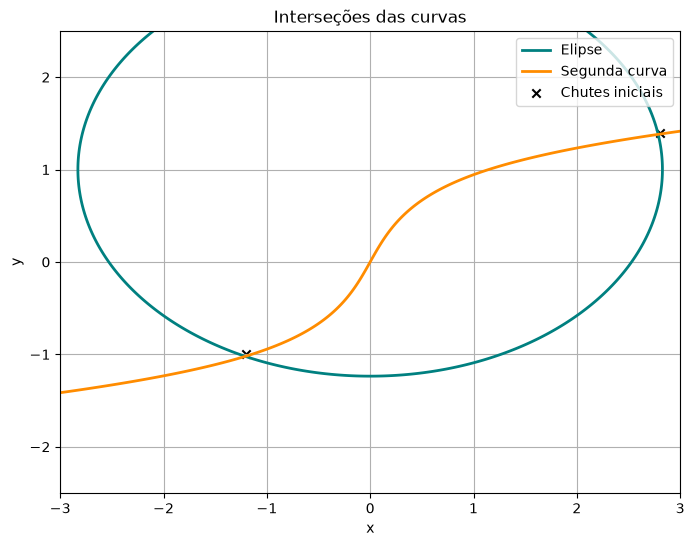

Chute inicial (-1.2, -1.0): x=-1.20854348, y=-1.02166742; iterações=4; resíduo=4.441e-16
Chute inicial (2.8, 1.4): x=2.78711154, y=1.38079625; iterações=4; resíduo=4.441e-16


In [2]:
import numpy as np
import matplotlib.pyplot as plt


def intersection_system(values):
    x_value, y_value = values
    return np.array(
        [
            x_value**2 / 8.0 + (y_value - 1.0) ** 2 / 5.0 - 1.0,
            np.arctan(x_value) + x_value - y_value - y_value**3,
        ],
        dtype=float,
    )


def intersection_jacobian(values):
    x_value, y_value = values
    return np.array(
        [
            [x_value / 4.0, 2.0 * (y_value - 1.0) / 5.0],
            [1.0 / (1.0 + x_value**2) + 1.0, -1.0 - 3.0 * y_value**2],
        ],
        dtype=float,
    )


def newton_system(initial, tolerance=1e-12, max_iterations=100):
    current = np.array(initial, dtype=float)
    for iteration in range(1, max_iterations + 1):
        correction = np.linalg.solve(
            intersection_jacobian(current),
            -intersection_system(current),
        )
        current += correction
        if np.linalg.norm(correction, ord=np.inf) < tolerance:
            residual = np.linalg.norm(intersection_system(current), ord=np.inf)
            return current, iteration, residual
    raise RuntimeError("Newton-Raphson não convergiu.")


x_grid = np.linspace(-3.0, 3.0, 601)
y_grid = np.linspace(-2.5, 2.5, 501)
X, Y = np.meshgrid(x_grid, y_grid)
curve_ellipse = X**2 / 8.0 + (Y - 1.0) ** 2 / 5.0 - 1.0
curve_cubic = np.arctan(X) + X - Y - Y**3

plt.figure(figsize=(8, 6))
plt.contour(X, Y, curve_ellipse, levels=[0], colors=["teal"], linewidths=2)
plt.contour(X, Y, curve_cubic, levels=[0], colors=["darkorange"], linewidths=2)
plt.plot([], [], color="teal", linewidth=2, label="Elipse")
plt.plot([], [], color="darkorange", linewidth=2, label="Segunda curva")
plt.scatter([-1.2, 2.8], [-1.0, 1.4], marker="x", color="black", label="Chutes iniciais")
plt.xlim(-3, 3)
plt.ylim(-2.5, 2.5)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Interseções das curvas")
plt.grid(True)
plt.legend()
plt.show()
plt.close()

initial_guesses = [(-1.2, -1.0), (2.8, 1.4)]
expected_roots = [(-1.2085435, -1.0216674), (2.7871115, 1.3807962)]
roots = []

for initial_guess, expected_root in zip(initial_guesses, expected_roots):
    root, iterations, residual = newton_system(initial_guess)
    assert residual < 1e-12
    assert np.allclose(root, expected_root, atol=1e-6)
    roots.append(root)
    print(
        f"Chute inicial {initial_guess}: "
        f"x={root[0]:.8f}, y={root[1]:.8f}; "
        f"iterações={iterations}; resíduo={residual:.3e}"
    )

## Atividade 4
Uma indústria consome energia elétrica de três usinas fornecedoras.  

O custo de fornecimento em reais por hora como função da potência consumida em kW é dada pelas seguintes funções:

$$
C_{1}(x) = 10 + 0.3x + 10^{-4}x^{2} + 3.4 \cdot 10^{-9}x^{4} \tag{5.61}
$$

$$
C_{2}(x) = 50 + 0.25x + 2 \cdot 10^{-4}x^{2} + 4.3 \cdot 10^{-7}x^{3}
$$

$$
C_{3}(x) = 500 + 0.19x + 5 \cdot 10^{-4}x^{2} + 1.1 \cdot 10^{-7}x^{4}
$$

Calcule a distribuição de consumo que produz custo mínimo quando a potência total consumida é **1500 kW**.  

Denote por $x_{1}, x_{2}, x_{3}$ as potências consumidas das usinas 1, 2 e 3, respectivamente.  

O custo total será dado por:

$$
C(x_{1},x_{2},x_{3}) = C_{1}(x_{1}) + C_{2}(x_{2}) + C_{3}(x_{3})
$$

Enquanto o consumo total é:

$$
G(x_{1},x_{2},x_{3}) = x_{1} + x_{2} + x_{3} - 1500 = 0
$$

Pelos multiplicadores de Lagrange, temos que resolver o sistema:

$$
\nabla C(x_{1},x_{2},x_{3}) = \lambda \nabla G(x_{1},x_{2},x_{3})
$$

$$
G(x_{1},x_{2},x_{3}) = 0
$$

**Resposta esperada:**

$$
(x_{1},x_{2},x_{3}) \approx (453.62, \; 901.94, \; 144.43)
$$

In [3]:
import numpy as np


TOTAL_POWER = 1_500.0


def stationarity_system(values):
    power_1, power_2, power_3, lagrange_multiplier = values
    marginal_cost_1 = 0.3 + 2e-4 * power_1 + 1.36e-8 * power_1**3
    marginal_cost_2 = 0.25 + 4e-4 * power_2 + 1.29e-6 * power_2**2
    marginal_cost_3 = 0.19 + 1e-3 * power_3 + 4.4e-7 * power_3**3

    return np.array(
        [
            marginal_cost_1 - lagrange_multiplier,
            marginal_cost_2 - lagrange_multiplier,
            marginal_cost_3 - lagrange_multiplier,
            power_1 + power_2 + power_3 - TOTAL_POWER,
        ],
        dtype=float,
    )


def stationarity_jacobian(values):
    power_1, power_2, power_3, _ = values
    second_derivative_1 = 2e-4 + 4.08e-8 * power_1**2
    second_derivative_2 = 4e-4 + 2.58e-6 * power_2
    second_derivative_3 = 1e-3 + 1.32e-6 * power_3**2

    return np.array(
        [
            [second_derivative_1, 0.0, 0.0, -1.0],
            [0.0, second_derivative_2, 0.0, -1.0],
            [0.0, 0.0, second_derivative_3, -1.0],
            [1.0, 1.0, 1.0, 0.0],
        ],
        dtype=float,
    )


def newton_lagrange(initial, tolerance=1e-11, max_iterations=100):
    values = np.array(initial, dtype=float)
    for iteration in range(1, max_iterations + 1):
        correction = np.linalg.solve(
            stationarity_jacobian(values),
            -stationarity_system(values),
        )
        values += correction
        if np.linalg.norm(correction, ord=np.inf) < tolerance:
            residual = np.linalg.norm(stationarity_system(values), ord=np.inf)
            return values, iteration, residual
    raise RuntimeError("Newton-Raphson não convergiu.")


def costs(powers):
    power_1, power_2, power_3 = powers
    cost_1 = 10 + 0.3 * power_1 + 1e-4 * power_1**2 + 3.4e-9 * power_1**4
    cost_2 = 50 + 0.25 * power_2 + 2e-4 * power_2**2 + 4.3e-7 * power_2**3
    cost_3 = 500 + 0.19 * power_3 + 5e-4 * power_3**2 + 1.1e-7 * power_3**4
    return cost_1, cost_2, cost_3


initial_guess = [453.6, 901.9, 144.5, 1.66]
solution, iterations, residual = newton_lagrange(initial_guess)
powers = solution[:3]
individual_costs = costs(powers)

assert np.all(powers > 0.0)
assert abs(np.sum(powers) - TOTAL_POWER) < 1e-9
assert residual < 1e-10
assert np.allclose(powers, [453.62, 901.94, 144.43], atol=0.02)

print("Distribuição ótima:")
for index, power in enumerate(powers, start=1):
    print(f"  x{index} = {power:.4f} kW")
print(f"Potência total = {np.sum(powers):.4f} kW")
print(f"Custo total = R$ {sum(individual_costs):.4f}/h")
print(f"Custo marginal comum (lambda) = R$ {solution[3]:.8f}/kWh")
print(f"Iterações = {iterations}; norma do resíduo = {residual:.3e}")

Distribuição ótima:
  x1 = 453.6224 kW
  x2 = 901.9432 kW
  x3 = 144.4344 kW
Potência total = 1500.0000 kW
Custo total = R$ 1650.0645/h
Custo marginal comum (lambda) = R$ 1.66019422/kWh
Iterações = 3; norma do resíduo = 0.000e+00


## Versionando o código

Submeta a branch para o servidor:

```bash
git add .
git commit -m "Semana 7"
git push origin semana7
```